In [6]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Загружаем предобработанные данные 
df = pd.read_csv("data/processed_train_data.csv")

# Проверяем размерность и распределение классов (встроенная проверка)
print(f"Датасет загружен: {df.shape[0]} строк, {df.shape[1]} столбцов")
print("\nРаспределение классов Transmission_Manual:")
print(df['Transmission_Manual'].value_counts(normalize=True))

# Подготовка признаков и целевой переменной
X = df.drop(['Price', 'Transmission_Manual'], axis=1)
y = df['Transmission_Manual']

# Создаем модель случайного леса с оценкой OOB
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, oob_score=True)

# Обучаем модель на всех данных
rf_model.fit(X, y)

# Выводим результаты оценки через OOB
print("\n" + "=" * 50)
print("ОЦЕНКА МОДЕЛИ ЧЕРЕЗ OOB-ДАННЫЕ:")
print("=" * 50)
print(f"OOB Accuracy: {rf_model.oob_score_:.4f}")
print(f"OOB Error Rate: {1 - rf_model.oob_score_:.4f}")
print(f"\nМодель правильно классифицирует ~{rf_model.oob_score_*100:.1f}% объектов, "
      f"которые не участвовали в обучении отдельных деревьев.")

Датасет загружен: 6019 строк, 25 столбцов

Распределение классов Transmission_Manual:
Transmission_Manual
True     0.714238
False    0.285762
Name: proportion, dtype: float64

ОЦЕНКА МОДЕЛИ ЧЕРЕЗ OOB-ДАННЫЕ:
OOB Accuracy: 0.9203
OOB Error Rate: 0.0797

Модель правильно классифицирует ~92.0% объектов, которые не участвовали в обучении отдельных деревьев.


In [3]:
# Подготовка данных 
X = df.drop(['Price', 'Transmission_Manual'], axis=1)
y = df['Transmission_Manual']

# AdaBoost Classifier
# n_estimators=100 - количество слабых моделей (деревьев)
# learning_rate=1.0 - скорость обучения (по умолчанию для AdaBoost)
ada_model = AdaBoostClassifier(n_estimators=100, random_state=42, learning_rate=1.0)
ada_model.fit(X, y)

print("AdaBoost Classifier:")
print(f"Train Accuracy: {ada_model.score(X, y):.4f}")

# Gradient Boosting Classifier
# n_estimators=100 - количество деревьев
# learning_rate=0.1 - шаг сходимости (меньше значение = медленнее, но стабильнее обучение)
gb_model = GradientBoostingClassifier(n_estimators=100, random_state=42, learning_rate=0.1)
gb_model.fit(X, y)

print("\nGradient Boosting Classifier:")
print(f"Train Accuracy: {gb_model.score(X, y):.4f}")

AdaBoost Classifier:
Train Accuracy: 0.8825

Gradient Boosting Classifier:
Train Accuracy: 0.9100


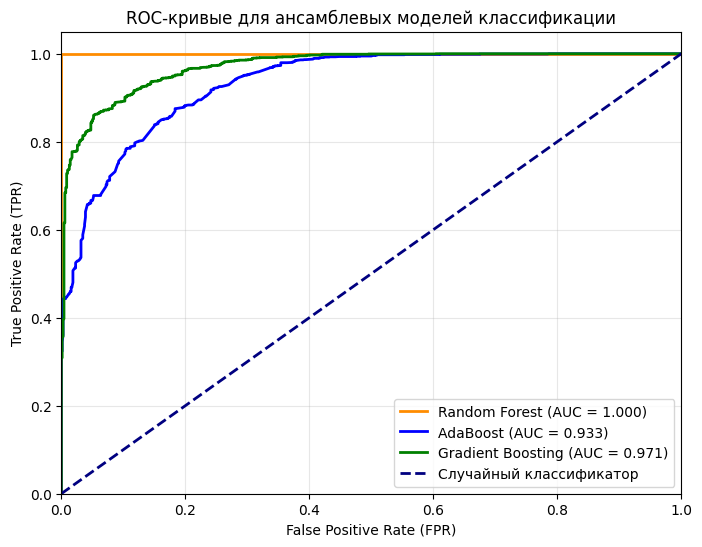

Результаты оценки:
Random Forest AUC:      1.000
AdaBoost AUC:           0.933
Gradient Boosting AUC:  0.971


In [7]:
# Подготовка данных (те же X_clf и y_clf, что использовались ранее)
X_clf = df.drop(['Price', 'Transmission_Manual'], axis=1)
y_clf = df['Transmission_Manual']

# Разделяем данные для оценки (используем тот же random_state для консистентности)
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.4, random_state=42
)

# Получаем вероятности для каждой модели
rf_proba = rf_model.predict_proba(X_test_clf)[:, 1]
ada_proba = ada_model.predict_proba(X_test_clf)[:, 1]
gb_proba = gb_model.predict_proba(X_test_clf)[:, 1]

# Вычисляем координаты ROC-кривых
fpr_rf, tpr_rf, _ = roc_curve(y_test_clf, rf_proba)
roc_auc_rf = auc(fpr_rf, tpr_rf)

fpr_ada, tpr_ada, _ = roc_curve(y_test_clf, ada_proba)
roc_auc_ada = auc(fpr_ada, tpr_ada)

fpr_gb, tpr_gb, _ = roc_curve(y_test_clf, gb_proba)
roc_auc_gb = auc(fpr_gb, tpr_gb)

# Строим сводный график ROC-кривых
plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, color='darkorange', lw=2, label=f'Random Forest (AUC = {roc_auc_rf:.3f})')
plt.plot(fpr_ada, tpr_ada, color='blue', lw=2, label=f'AdaBoost (AUC = {roc_auc_ada:.3f})')
plt.plot(fpr_gb, tpr_gb, color='green', lw=2, label=f'Gradient Boosting (AUC = {roc_auc_gb:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Случайный классификатор')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC-кривые для ансамблевых моделей классификации')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

print("Результаты оценки:")
print(f"Random Forest AUC:      {roc_auc_rf:.3f}")
print(f"AdaBoost AUC:           {roc_auc_ada:.3f}")
print(f"Gradient Boosting AUC:  {roc_auc_gb:.3f}")

Найдены признаки с потенциальной утечкой данных: []
Эти признаки будут исключены из обучения.


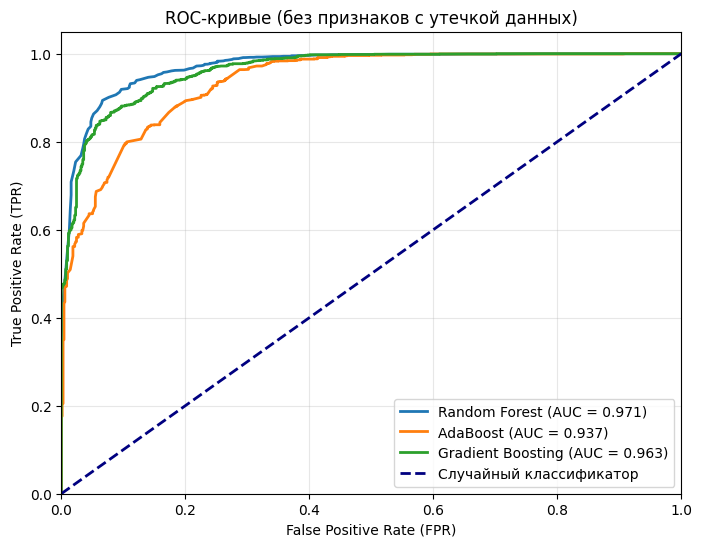

In [8]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Загружаем данные заново, чтобы иметь чистый исходник
df = pd.read_csv("data/processed_train_data.csv")

# Находим признаки с абсолютной корреляцией > 0.95 с целевой переменной
target = 'Transmission_Manual'
correlations = df.drop(columns=[target]).corrwith(df[target]).abs()
leak_features = correlations[correlations > 0.95].index.tolist()

print(f"Найдены признаки с потенциальной утечкой данных: {leak_features}")
print("Эти признаки будут исключены из обучения.")

# Удаляем найденные признаки и саму целевую переменную из X
X_clean = df.drop(columns=[target] + leak_features)
y = df[target]

# Разделяем выборку (тот же random_state для консистентности)
X_train, X_test, y_train, y_test = train_test_split(X_clean, y, test_size=0.4, random_state=42)

# Обучаем модели на очищенных данных
models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

plt.figure(figsize=(8, 6))

for name, model in models.items():
    model.fit(X_train, y_train)
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Случайный классификатор')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC-кривые (без признаков с утечкой данных)')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()